# Dense Transformer GPU Scaling Calculator

## Overview

This notebook estimates the number of GPUs required to train dense transformer models as a function of model size, training dataset size, model FLOPs utilization, and available training time.

Three resource estimates are calculated via simple heuristics:

1. **Compute-limited GPUs:** The number of GPUs required to complete training within a specified time.
2. **Memory-limited GPUs:** The number of GPUs required to hold the model's training state.
3. **Combined GPUs:** The maximum of the compute and memory requirements.

## 1. Training Dataset Size

Following the compute-optimal scaling results of Hoffmann et al. (2022), a useful approximation is to train a model on approximately 20 tokens per parameter:

$$
D = rN
$$

where:

- $N$ is the number of model parameters.
- $D$ is the number of training tokens.
- $r$ is the number of training tokens per parameter, typically 20.

The ratio is configurable. The 20:1 heuristic is associated with compute-optimal training under the assumptions of the Chinchilla study, rather than a universal saturation limit.

## 2. Training Compute

The total floating-point operations required to train a dense transformer can be approximated as

$$
F_{\mathrm{train}} \approx 6ND = 6rN^2.
$$

This approximation counts roughly two floating-point operations per parameter per token in the forward pass and four in the backward pass.

For a fixed tokens-per-parameter ratio, training compute therefore grows quadratically with parameter count.

Let $P$ denote the peak dense BF16 throughput of one GPU in FLOP/s, $\eta$ the achieved model FLOPs utilization, and $t$ the training duration in days.

The compute-limited GPU count is

$$
\boxed{
G_{\mathrm{compute}} =
\left\lceil
\frac{6rN^2}{86400\,t\,\eta P}
\right\rceil
}
$$

The utilization factor accounts approximately for the difference between theoretical peak compute and achieved training throughput.

## 3. Training Memory

Following the mixed-precision Adam memory accounting described by Rajbhandari et al. (2020), the model's training state can be estimated using 16 bytes per parameter.

| Component | Bytes per parameter |
|---|---:|
| BF16 model weights | 2 |
| BF16 gradients | 2 |
| FP32 master weights | 4 |
| FP32 Adam first moment | 4 |
| FP32 Adam second moment | 4 |
| **Total** | **16** |

Thus,

$$
M_{\mathrm{train}} \approx 16N \text{ bytes}.
$$

This assumes an optimizer implementation that maintains FP32 master weights. Implementations without a separate master copy can require less memory.

Assuming training states can be fully sharded across GPUs, the memory-limited GPU count is

$$
\boxed{
G_{\mathrm{memory}} =
\left\lceil
\frac{16N}{M_{\mathrm{GPU}}(1-f)}
\right\rceil
}
$$

where $M_{\mathrm{GPU}}$ is GPU memory capacity in bytes and $f$ is the fraction reserved for activations, temporary buffers, and runtime overhead.

The default reserve is 25%.

## 4. Combined GPU Requirement

The final GPU count is estimated as

$$
G_{\mathrm{required}} =
\max(G_{\mathrm{compute}},G_{\mathrm{memory}})
$$

## 5. Assumptions

The calculator is intended for initial infrastructure sizing and comparisons, not detailed cluster design.

- Models are dense, decoder-only transformers trained from scratch.
- Compute estimates use dense BF16 Tensor Core throughput.
- Training uses AdamW with 16 bytes per parameter of model state.
- Memory is assumed to be fully shardable across GPUs.
- Activation memory is represented by a fixed reserve rather than calculated explicitly.
- Communication overhead, interconnect topology, and distributed scaling efficiency are not modeled.
- GPU specifications are approximate planning values.
- GPU counts are mathematical lower-bound estimates under these assumptions, not guaranteed feasible training configurations.

## References

1. Hoffmann, J., et al. (2022). *Training Compute-Optimal Large Language Models.* Advances in Neural Information Processing Systems (NeurIPS). https://arxiv.org/abs/2203.15556

   Source for the approximately 20 tokens-per-parameter heuristic and discussion of the $6ND$ training FLOPs approximation.

2. Kaplan, J., et al. (2020). *Scaling Laws for Neural Language Models.* https://arxiv.org/abs/2001.08361

   Early empirical scaling-law analysis and the widely used approximate transformer training compute model.

3. Rajbhandari, S., Rasley, J., Ruwase, O., & He, Y. (2020). *ZeRO: Memory Optimizations Toward Training Trillion Parameter Models.* Proceedings of SC20. https://arxiv.org/abs/1910.02054

   Source for mixed-precision Adam memory accounting and sharding model states across GPUs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------------------------------------------------
# GPU specifications
# -----------------------------------------------------------------------------

# Peak dense BF16 throughput (TFLOP/s) and memory (GB).
# RTX 5090 BF16 throughput is an approximate planning value.
gpus = {
    'RTX 5090': {'tflops': 210, 'memory': 32},
    'A100 80GB': {'tflops': 312, 'memory': 80},
    'H100 SXM': {'tflops': 989, 'memory': 80},
    'H200 SXM': {'tflops': 989, 'memory': 141},
    'B300 SXM': {'tflops': 2250, 'memory': 270},
}


def gpu_scaling(
    parameters=7e9,
    tokens_per_parameter=20,
    eta=0.40,
    days=30,
    bytes_per_parameter=16,
    memory_reserve=0.25,
):
    """Estimate compute, memory, and combined GPU requirements."""

    # Training compute and memory
    tokens = parameters * tokens_per_parameter
    flops = 6 * parameters * tokens
    memory_gb = parameters * bytes_per_parameter / 1e9
    seconds = days * 86400

    # Model sizes for plots
    model_sizes = np.logspace(8, 11, 200)
    model_flops = 6 * tokens_per_parameter * model_sizes**2
    model_memory = model_sizes * bytes_per_parameter / 1e9

    # Calculate GPU counts
    results = {}
    curves = {}

    for name, gpu in gpus.items():
        effective_flops = gpu['tflops'] * 1e12 * eta
        usable_memory = gpu['memory'] * (1 - memory_reserve)

        # Selected model
        n_compute = int(np.ceil(flops / (seconds * effective_flops)))
        n_memory = int(np.ceil(memory_gb / usable_memory))
        n_total = max(n_compute, n_memory)

        results[name] = (n_compute, n_memory, n_total)

        # Scaling curves
        compute_curve = np.ceil(model_flops / (seconds * effective_flops))
        memory_curve = np.ceil(model_memory / usable_memory)

        curves[name] = (
            compute_curve,
            memory_curve,
            np.maximum(compute_curve, memory_curve),
        )

    # Print results
    print(f'Parameters:       {parameters / 1e9:.2f}B')
    print(f'Training tokens:  {tokens / 1e9:.2f}B')
    print(f'Training compute: {flops / 1e21:.3f} ZFLOPs')
    print(f'Training memory:  {memory_gb:.1f} GB')
    print(f'Training time:    {days} days')
    print(f'MFU:              {eta:.0%}\n')

    print(f'{"GPU":<15} {"Compute":>10} {"Memory":>10} {"Combined":>10}')
    print('-' * 48)

    for name, (nc, nm, nt) in results.items():
        print(f'{name:<15} {nc:>10} {nm:>10} {nt:>10}')

    # Plot all three constraints
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    titles = [
        'Compute-Limited GPUs',
        'Memory-Limited GPUs',
        'Combined GPU Requirement',
    ]

    for i, ax in enumerate(axes):
        for name, curve in curves.items():
            ax.plot(model_sizes / 1e9, curve[i], label=name)

        ax.axvline(
            parameters / 1e9,
            color='gray',
            linestyle='--',
            alpha=0.7,
        )

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel('Model parameters (billions)')
        ax.set_ylabel('Required GPUs')
        ax.set_title(titles[i])
        ax.grid(True, which='both', alpha=0.3)

    axes[0].legend()
    fig.suptitle(
        f'Dense Transformer Scaling | {parameters / 1e9:.2f}B parameters | '
        f'{days:.2f} day experiment | FLOPs Utilization={eta:.2%} | '
        f'{tokens_per_parameter:.2f} tokens/parameter'
    )

    plt.tight_layout()
    plt.show()

    return results


## Common Parameters

In [2]:
tokens_per_parameter = 20
eta = 0.5
deadlines_days = [1, 7, 14]

## 100M Parameter Models

Parameters:       0.10B
Training tokens:  2.00B
Training compute: 0.001 ZFLOPs
Training memory:  1.6 GB
Training time:    1 days
MFU:              50%

GPU                Compute     Memory   Combined
------------------------------------------------
RTX 5090                 1          1          1
A100 80GB                1          1          1
H100 SXM                 1          1          1
H200 SXM                 1          1          1
B300 SXM                 1          1          1


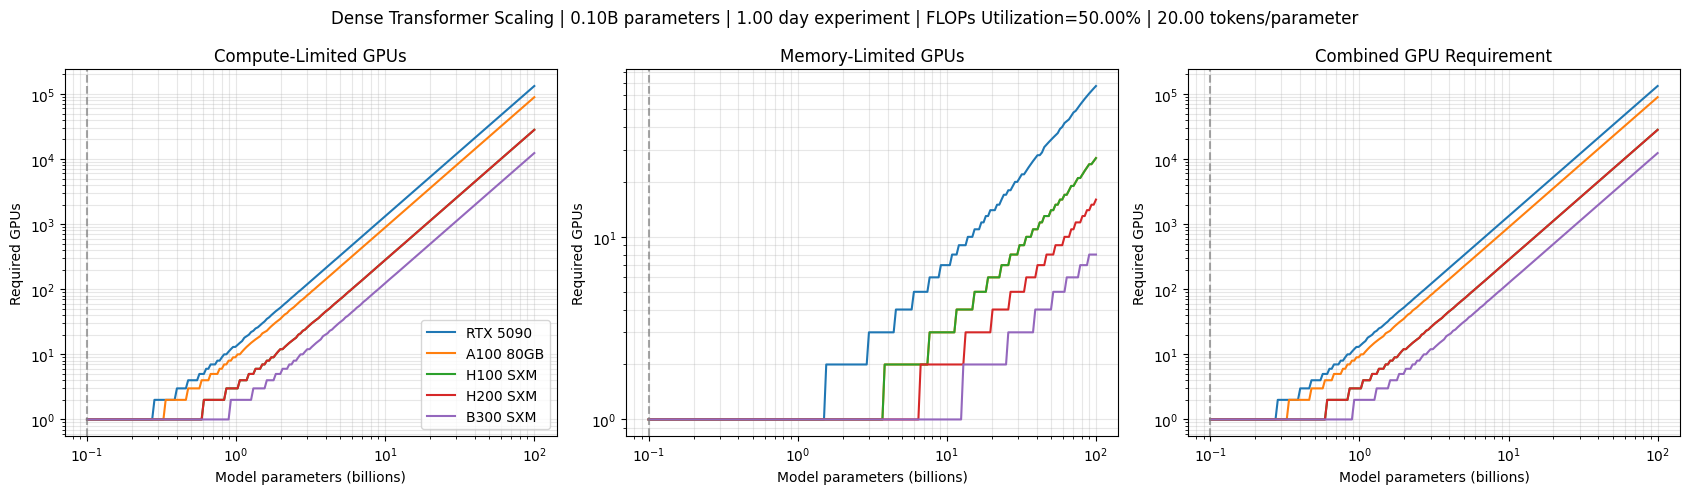

Parameters:       0.10B
Training tokens:  2.00B
Training compute: 0.001 ZFLOPs
Training memory:  1.6 GB
Training time:    7 days
MFU:              50%

GPU                Compute     Memory   Combined
------------------------------------------------
RTX 5090                 1          1          1
A100 80GB                1          1          1
H100 SXM                 1          1          1
H200 SXM                 1          1          1
B300 SXM                 1          1          1


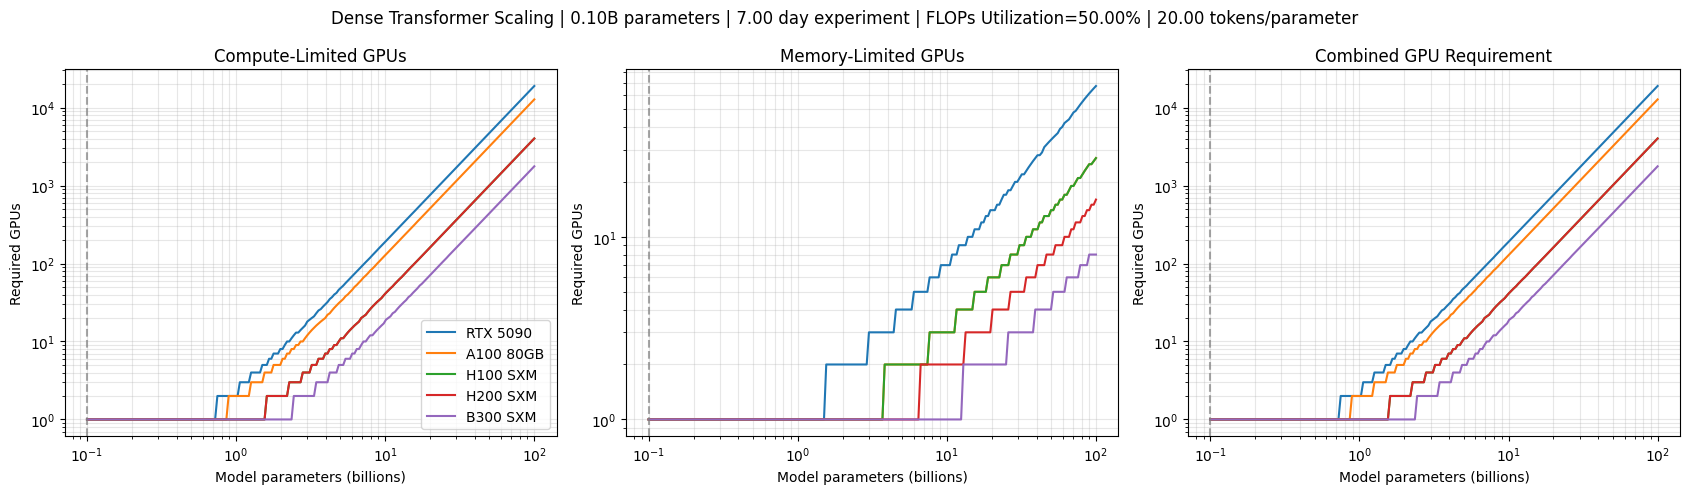

Parameters:       0.10B
Training tokens:  2.00B
Training compute: 0.001 ZFLOPs
Training memory:  1.6 GB
Training time:    14 days
MFU:              50%

GPU                Compute     Memory   Combined
------------------------------------------------
RTX 5090                 1          1          1
A100 80GB                1          1          1
H100 SXM                 1          1          1
H200 SXM                 1          1          1
B300 SXM                 1          1          1


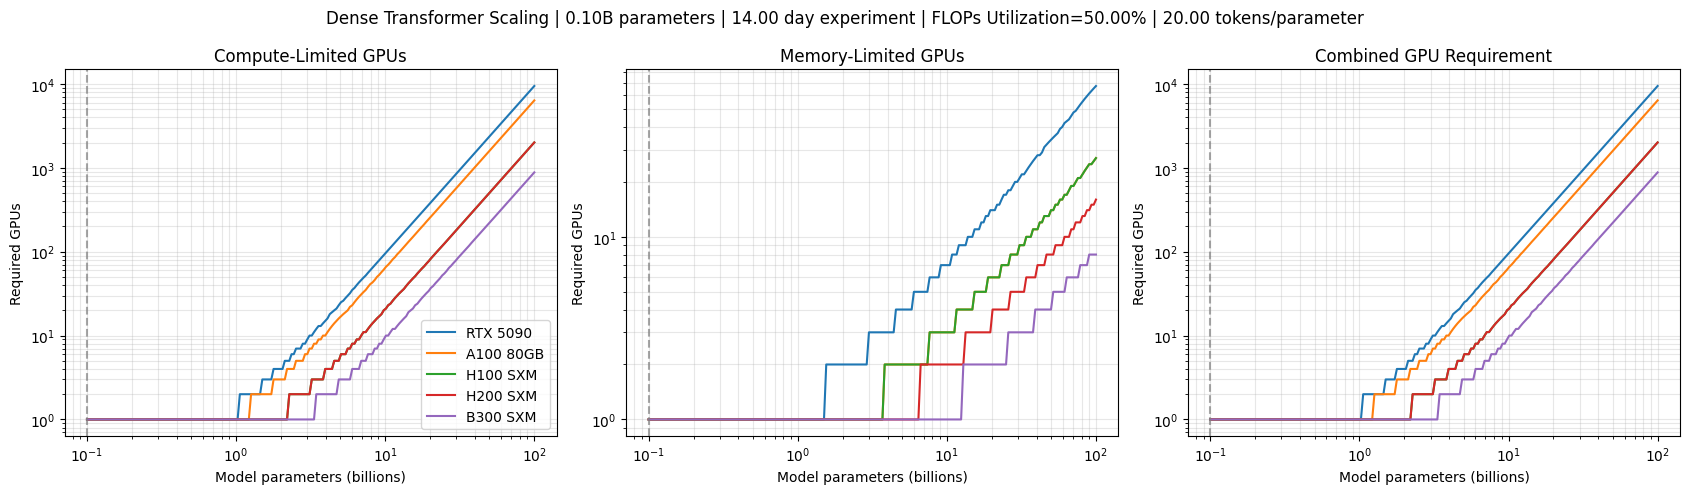

In [3]:
parameters = 100e6

for deadline in deadlines_days:
    results = gpu_scaling(
        parameters=parameters,
        tokens_per_parameter=tokens_per_parameter,
        eta=eta,
        days=deadline,
    )